# Laboratorio 9 - Deep Learning

- Juan Solís - 23720
- Victor Pérez - 23731
- Diego Flores - 23714
- Nils Muralles - 23727
- Isabella Recinos - 23003

## Task 2

### Task 2.1

Se carga Fashion-MNIST (60 000 imágenes de entrenamiento) escalada a [−1, 1]. Se construye el calendario lineal de $\beta_t$, junto con $\alpha_t$ y $\bar\alpha_t$, y la función `q_sample` con la fórmula cerrada $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$. Los tensores usan índice 0, por lo que el instante $t$ se guarda en la posición $t-1$.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from torchvision import datasets

# Semilla
SEED = 42
torch.manual_seed(SEED)

# Escalado a [-1, 1]
data = datasets.FashionMNIST("data", train=True, download=True)
X = data.data.float() / 255.0 * 2 - 1  # (60000, 28, 28)
Y = data.targets
class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

T = 1000
beta_start = 1e-4
beta_end = 0.02

# Calendario lineal (índice 0 <-> t = 1)
betas = torch.linspace(beta_start, beta_end, T, dtype=torch.float64)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)
t_axis = torch.arange(1, T + 1)

def q_sample(x0, t, eps, alpha_bar=alpha_bar):
    """x_t = sqrt(alpha_bar_t) x0 + sqrt(1 - alpha_bar_t) eps, con t en {1, ..., T}."""
    ab = alpha_bar[t - 1].to(x0.dtype).view(-1, *([1] * (x0.dim() - 1)))
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

print("X:", tuple(X.shape), "rango:", X.min().item(), X.max().item(), "| semilla:", SEED)
print(f"beta_1 = {betas[0]:.1e}, beta_T = {betas[-1]:.1e}, alpha_bar_T = {alpha_bar[-1]:.4e}")

# Prueba rápida de q_sample con un lote y t distintos
x0 = X[:4]
t = torch.tensor([1, 10, 500, 1000])
xt = q_sample(x0, t, torch.randn_like(x0))
print("x_t:", tuple(xt.shape))

X: (60000, 28, 28) rango: -1.0 1.0 | semilla: 42
beta_1 = 1.0e-04, beta_T = 2.0e-02, alpha_bar_T = 4.0358e-05
x_t: (4, 28, 28)


### Task 2.2

Se toma la primera imagen de entrenamiento como $x_0$, se replican 5 000 copias y se aplica 300 veces el paso $x_s = \sqrt{\alpha_s}\,x_{s-1} + \sqrt{\beta_s}\,\epsilon_s$ con ruido independiente por paso y por copia. Luego se comparan la media y la varianza empíricas por píxel contra los valores teóricos.

**a.** Proceso paso a paso.

In [2]:
# a. 5 000 copias de x0, 300 pasos con ruido independiente
N, t_obj = 5000, 300
x0 = X[0]
x = x0.expand(N, 28, 28).clone()
for s in range(1, t_obj + 1):
    x = alphas[s - 1].sqrt().float() * x + betas[s - 1].sqrt().float() * torch.randn_like(x)
print("Clase de x0:", class_names[int(Y[0])], "| copias:", tuple(x.shape))

Clase de x0: Boot | copias: (5000, 28, 28)


**b.** Media y varianza empíricas por píxel frente a las teóricas.

In [3]:
# b. Comparación con sqrt(alpha_bar_300) x0 y 1 - alpha_bar_300
ab300 = alpha_bar[t_obj - 1].item()
mean_emp = x.mean(dim=0)
var_emp = x.var(dim=0)
mean_teo = math.sqrt(ab300) * x0
var_teo = 1 - ab300

err_mean = (mean_emp - mean_teo).abs()
print(f"alpha_bar_300 = {ab300:.6f}")
print(f"Error máximo absoluto de la media = {err_mean.max().item():.5f}")
print(f"Varianza empírica promedio = {var_emp.mean().item():.5f} | teórica = {var_teo:.5f}")
print(f"Error relativo de la varianza promedio = {abs(var_emp.mean().item() - var_teo) / var_teo:.2e}")

alpha_bar_300 = 0.396420
Error máximo absoluto de la media = 0.03539
Varianza empírica promedio = 0.60406 | teórica = 0.60358
Error relativo de la varianza promedio = 7.97e-04


**c.** Error de la media frente al error estándar de un promedio de 5 000 muestras.

In [4]:
# c. Error estándar por píxel y máximo esperado sobre 784 píxeles
se = math.sqrt(var_teo / N)
max_esperado = se * math.sqrt(2 * math.log(784))  # orden del máximo de 784 |N(0, se^2)|
print(f"Error estándar = sqrt({var_teo:.4f} / {N}) = {se:.5f}")
print(f"Error medio absoluto = {err_mean.mean().item():.5f} | esperado se*sqrt(2/pi) = {se * math.sqrt(2 / math.pi):.5f}")
print(f"Error máximo / se = {err_mean.max().item() / se:.2f} | máximo esperado aprox. {max_esperado:.5f} ({max_esperado / se:.2f} se)")
print(f"Fracción de píxeles con error < 2 se = {(err_mean < 2 * se).float().mean().item():.3f} (esperado 0.954)")

Error estándar = sqrt(0.6036 / 5000) = 0.01099
Error medio absoluto = 0.00899 | esperado se*sqrt(2/pi) = 0.00877
Error máximo / se = 3.22 | máximo esperado aprox. 0.04011 (3.65 se)
Fracción de píxeles con error < 2 se = 0.954 (esperado 0.954)


**Respuesta 2.2 (b y c).**

Con $x_0$ una imagen de la clase Boot y $\bar\alpha_{300} = 0.39642$:

- Error máximo absoluto de la media: **0.0354**.
- Varianza empírica promedio: **0.60406** frente a la teórica $1 - \bar\alpha_{300} = 0.60358$, un error relativo de $8\times10^{-4}$.

Cada píxel de $x_{300}$ es gaussiano con varianza $\sigma^2 = 1 - \bar\alpha_{300} = 0.6036$. Por eso el promedio de $N = 5000$ copias tiene error estándar

$$\mathrm{SE} = \sqrt{\frac{\sigma^2}{N}} = \sqrt{\frac{0.6036}{5000}} = 0.01099.$$

- El error medio absoluto observado (0.00899) coincide con el esperado de una normal, $\mathrm{SE}\sqrt{2/\pi} = 0.00877$.
- El 95.4 % de los píxeles tiene un error menor que $2\,\mathrm{SE}$, justo lo esperado para una normal.
- El error máximo se toma sobre 784 píxeles independientes. El máximo de 784 valores $|\mathcal N(0,\mathrm{SE}^2)|$ es del orden de $\mathrm{SE}\sqrt{2\ln 784} \approx 3.65\,\mathrm{SE} = 0.040$. El observado, $0.0354 = 3.22\,\mathrm{SE}$, está dentro de ese rango.

Por lo tanto, el error de la media es compatible con el ruido de muestreo y no indica un sesgo de la fórmula cerrada. Lo mismo ocurre con la varianza:

- Error estándar de la varianza por píxel: $\sigma^2\sqrt{2/(N-1)} \approx 0.0121$.
- Promediado sobre 784 píxeles: $0.0121/\sqrt{784} \approx 0.00043$.
- La diferencia observada, 0.00048, equivale a unos $1.1$ errores estándar.

### Task 2.3

Se visualiza $x_t$ con la fórmula cerrada para tres clases (T-shirt, Sneaker y Bag), usando el mismo $\epsilon$ en todos los instantes de cada imagen. Después se grafican $\bar\alpha_t$ y $\mathrm{SNR}(t)$ y se reportan los umbrales pedidos.

**a.** $x_t$ para $t \in \{1, 50, 100, 250, 500, 750, 1000\}$.

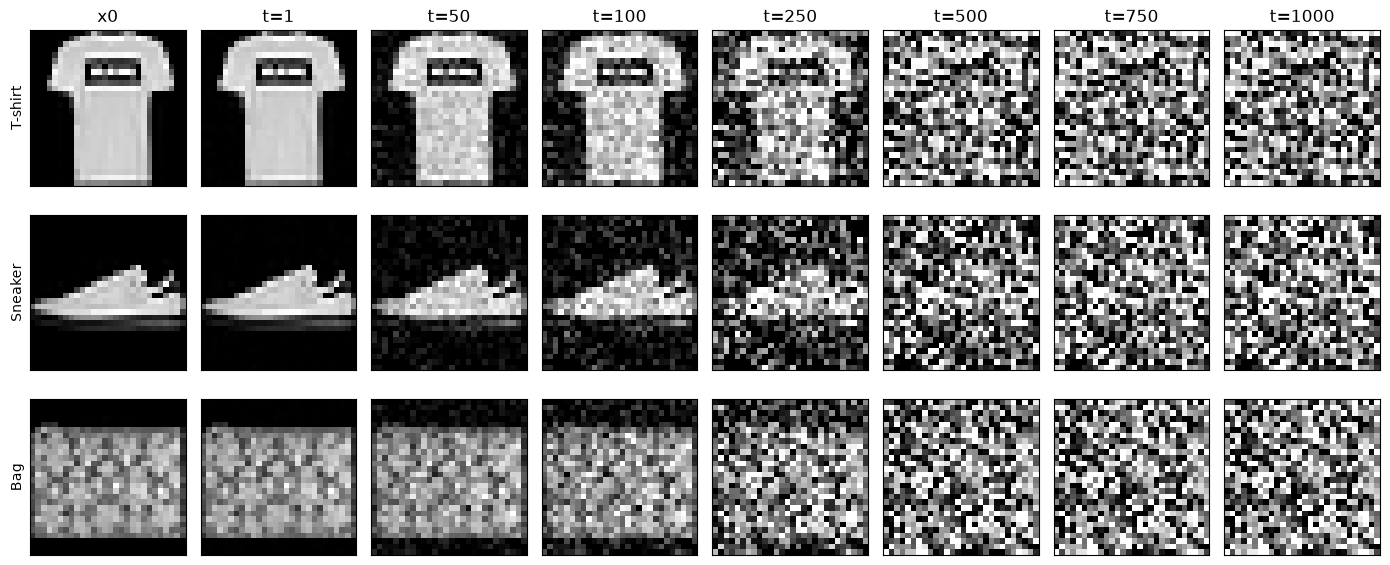

In [5]:
# a. Una imagen de cada clase elegida
ts = [1, 50, 100, 250, 500, 750, 1000]
clases = [0, 7, 8]
idx = [int((Y == c).nonzero()[0]) for c in clases]

torch.manual_seed(SEED)
fig, axs = plt.subplots(len(idx), len(ts) + 1, figsize=(14, 6))
for i, k in enumerate(idx):
    x0 = X[k]
    eps = torch.randn_like(x0)
    axs[i, 0].imshow(x0, cmap="gray", vmin=-1, vmax=1)
    axs[i, 0].set_ylabel(class_names[int(Y[k])])
    for j, t in enumerate(ts):
        xt = q_sample(x0[None], torch.tensor([t]), eps[None])[0]
        axs[i, j + 1].imshow(xt.clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
        if i == 0:
            axs[i, j + 1].set_title(f"t={t}")
axs[0, 0].set_title("x0")
for a in axs.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()

**b.** $\bar\alpha_t$ y $\mathrm{SNR}(t) = \bar\alpha_t / (1 - \bar\alpha_t)$, con el SNR en escala logarítmica.

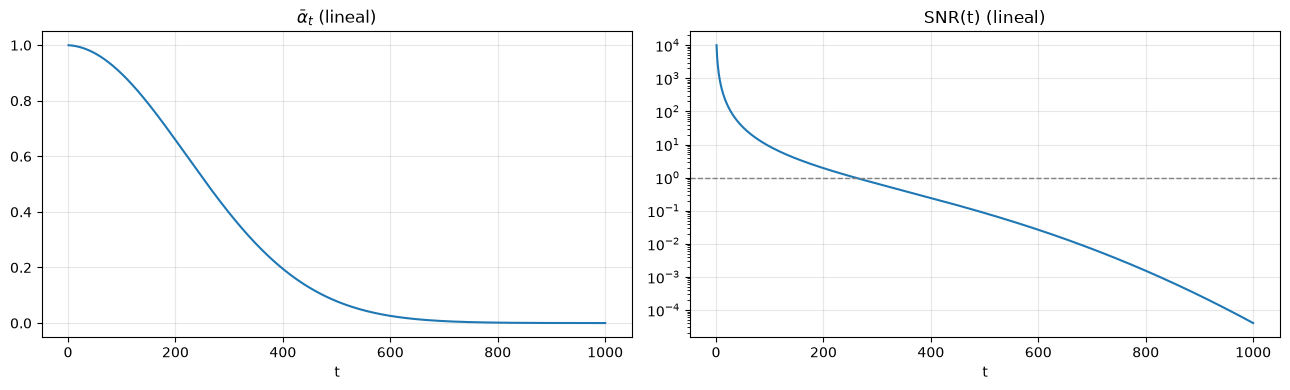

In [6]:
# b. alpha_bar_t y SNR(t)
snr = alpha_bar / (1 - alpha_bar)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(t_axis, alpha_bar)
axs[0].set_title(r"$\bar\alpha_t$ (lineal)"); axs[0].set_xlabel("t")
axs[1].plot(t_axis, snr)
axs[1].axhline(1, color="gray", ls="--", lw=1)
axs[1].set_yscale("log")
axs[1].set_title("SNR(t) (lineal)"); axs[1].set_xlabel("t")
for a in axs:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**c.** Primer $t$ con $\mathrm{SNR}(t) < 1$ y primer $t$ con $\bar\alpha_t < 0.01$.

In [7]:
# c. Umbrales
def primer_t(mask):
    return int(t_axis[mask][0])

t_snr1 = primer_t(snr < 1)
t_ab001 = primer_t(alpha_bar < 0.01)
print(f"Primer t con SNR < 1: {t_snr1} (alpha_bar = {alpha_bar[t_snr1 - 1]:.4f})")
print(f"Primer t con alpha_bar < 0.01: {t_ab001} (alpha_bar = {alpha_bar[t_ab001 - 1]:.5f})")

Primer t con SNR < 1: 260 (alpha_bar = 0.4976)
Primer t con alpha_bar < 0.01: 674 (alpha_bar = 0.00999)


### Task 2.4

Se parte del calendario coseno de Nichol & Dhariwal (2021), *Improved Denoising Diffusion Probabilistic Models*:

$$\bar\alpha_t = \frac{f(t)}{f(0)}, \qquad f(t) = \cos^2\!\left(\frac{t/T + s}{1 + s}\cdot\frac{\pi}{2}\right), \qquad s = 0.008$$

En el original $\bar\alpha_T = 0$ exactamente, por lo que $\beta_T = 1$ y hay que recortar $\beta_t$ a 0.999. **Modificación:** se reemplaza el ángulo final $\pi/2$ por $\varphi_{\max} = \arccos\sqrt{\bar\alpha_{\text{obj}}}$ con $\bar\alpha_{\text{obj}} = 10^{-4}$:

$$f(t) = \cos^2\!\left(\frac{t/T + s}{1 + s}\cdot\varphi_{\max}\right)$$

Así $\bar\alpha_T \approx 10^{-4} < 10^{-3}$ sin recorte y todos los $\beta_t = 1 - \bar\alpha_t/\bar\alpha_{t-1}$ quedan en $(0,1)$. Después se recalcula $\bar\alpha_t$ como $\prod_s (1-\beta_s)$ para que sea coherente con los $\beta_t$.

beta_t en [4.08e-05, 0.2502]


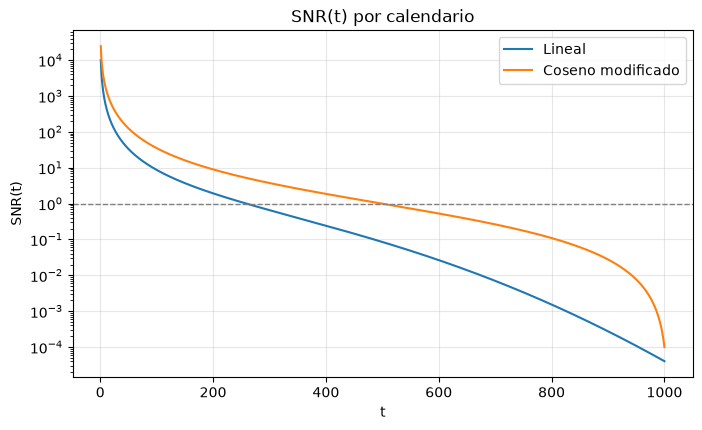

Lineal             alpha_bar_T = 4.0358e-05 | primer t con SNR < 1 = 260
Coseno modificado  alpha_bar_T = 1.0002e-04 | primer t con SNR < 1 = 500


In [8]:
# Calendario coseno modificado
s_cos = 0.008
alpha_bar_obj = 1e-4
phi_max = math.acos(math.sqrt(alpha_bar_obj))

t_cont = torch.arange(0, T + 1, dtype=torch.float64)
f = torch.cos((t_cont / T + s_cos) / (1 + s_cos) * phi_max) ** 2
ab_cont = f / f[0]
betas_cos = 1 - ab_cont[1:] / ab_cont[:-1]
alpha_bar_cos = torch.cumprod(1 - betas_cos, dim=0)
snr_cos = alpha_bar_cos / (1 - alpha_bar_cos)

assert ((betas_cos > 0) & (betas_cos < 1)).all() and alpha_bar_cos[-1] < 1e-3
print(f"beta_t en [{betas_cos.min():.2e}, {betas_cos.max():.4f}]")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(t_axis, snr, label="Lineal")
ax.plot(t_axis, snr_cos, label="Coseno modificado")
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_yscale("log"); ax.set_xlabel("t"); ax.set_ylabel("SNR(t)")
ax.set_title("SNR(t) por calendario"); ax.grid(alpha=0.3); ax.legend()
plt.show()

for nombre, ab, sn in [("Lineal", alpha_bar, snr), ("Coseno modificado", alpha_bar_cos, snr_cos)]:
    print(f"{nombre:18s} alpha_bar_T = {ab[-1]:.4e} | primer t con SNR < 1 = {primer_t(sn < 1)}")

### Task 2.5

**a.** Aproximación de $\bar\alpha_T$ para el calendario lineal.

Para el calendario lineal, $\beta_t = \beta_1 + (t-1)\Delta$ con $\Delta = \dfrac{\beta_T - \beta_1}{T-1}$, $\beta_1 = 10^{-4}$, $\beta_T = 0.02$ y $T = 1000$.

**Primera suma (aritmética).** Es la suma de una progresión aritmética: el número de términos por el promedio del primero y el último.

$$\sum_{t=1}^{T}\beta_t = T\,\frac{\beta_1 + \beta_T}{2} = 1000\cdot\frac{0.0001 + 0.02}{2} = 1000 \cdot 0.01005 = 10.05$$

**Segunda suma (aproximación integral).** Con $u = t/T \in [0,1]$, $\beta(u) \approx \beta_1 + (\beta_T - \beta_1)u$, y cada término ocupa un ancho $1/T$:

$$\sum_{t=1}^{T}\beta_t^2 \approx T\int_0^1 \big(\beta_1 + (\beta_T-\beta_1)u\big)^2 du = T\,\frac{\beta_T^3 - \beta_1^3}{3(\beta_T - \beta_1)}$$

$$= 1000\cdot\frac{8\times10^{-6} - 10^{-12}}{3\cdot 0.0199} = 1000\cdot\frac{8\times10^{-6}}{0.0597} \approx 0.1340$$

**Aproximación de $\bar\alpha_T$.**

$$\log\bar\alpha_T \approx -10.05 - \tfrac{1}{2}(0.1340) = -10.05 - 0.0670 = -10.117$$

$$\bar\alpha_T \approx e^{-10.117} = e^{-10}\cdot e^{-0.117} \approx 4.540\times10^{-5}\cdot 0.8896 \approx 4.04\times10^{-5}$$

**Comparación con el código** (celda siguiente):

- $\sum_t\beta_t = 10.0500$, exacta.
- $\sum_t\beta_t^2 = 0.13407$, frente a 0.13400 de la integral.
- $\log\bar\alpha_T = -10.11771$.
- $\bar\alpha_T = 4.0358\times10^{-5}$, frente a la aproximación $4.0387\times10^{-5}$: un error relativo del 0.07 %.

La diferencia restante se debe sobre todo al término siguiente de la serie de $\log(1-\beta)$, que es $-\tfrac13\sum_t\beta_t^3 \approx -0.0007$.

In [9]:
# a. Comparación de la aproximación a mano con el valor numérico
suma1 = T * (beta_start + beta_end) / 2
suma2 = T * (beta_end**3 - beta_start**3) / (3 * (beta_end - beta_start))
log_aprox = -suma1 - suma2 / 2
print(f"Suma beta: a mano = {suma1:.4f} | código = {betas.sum():.4f}")
print(f"Suma beta^2: integral = {suma2:.5f} | código = {(betas**2).sum():.5f}")
print(f"log alpha_bar_T: aprox = {log_aprox:.5f} | exacto = {alpha_bar[-1].log():.5f}")
print(f"alpha_bar_T: aprox = {math.exp(log_aprox):.4e} | exacto = {alpha_bar[-1]:.4e}")
print(f"Error relativo = {abs(math.exp(log_aprox) - alpha_bar[-1].item()) / alpha_bar[-1].item():.2%}")

Suma beta: a mano = 10.0500 | código = 10.0500
Suma beta^2: integral = 0.13400 | código = 0.13407
log alpha_bar_T: aprox = -10.11700 | exacto = -10.11771
alpha_bar_T: aprox = 4.0387e-05 | exacto = 4.0358e-05
Error relativo = 0.07%


**b.** Pasos con $\mathrm{SNR}(t) \in [0.01, 100]$ por calendario.

In [10]:
# b. Conteo por régimen de SNR
for nombre, sn in [("Lineal", snr), ("Coseno modificado", snr_cos)]:
    medio = ((sn >= 0.01) & (sn <= 100)).sum().item()
    alto = (sn > 100).sum().item()
    bajo = (sn < 0.01).sum().item()
    print(f"{nombre:18s} SNR>100: {alto:4d} | SNR en [0.01, 100]: {medio:4d} | SNR<0.01: {bajo:4d}")

Lineal             SNR>100:   27 | SNR en [0.01, 100]:  647 | SNR<0.01:  326
Coseno modificado  SNR>100:   56 | SNR en [0.01, 100]:  886 | SNR<0.01:   58


**Respuesta 2.5 b.**

| Calendario | SNR > 100 | SNR ∈ [0.01, 100] | SNR < 0.01 |
|---|---|---|---|
| Lineal | 27 | **647** | 326 |
| Coseno modificado | 56 | **886** | 58 |

**Régimen SNR ≪ 0.01** ($x_t \approx \epsilon$). Predecir $\epsilon$ es trivial: como $x_t = \sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$ con $\sqrt{1-\bar\alpha_t}\approx 1$, la red casi acierta devolviendo $\hat\epsilon = x_t$. La pérdida es pequeña desde el inicio, el gradiente apenas contiene información sobre la estructura de las imágenes y el paso aporta muy poco al aprendizaje.

**Régimen SNR ≫ 100** ($x_t \approx x_0$). Aquí el ruido es una perturbación diminuta sobre una imagen limpia. Aislarlo es difícil: la red tiene que separar una componente de amplitud $\sqrt{1-\bar\alpha_t}$ muy pequeña, casi como ruido de alta frecuencia, sin aprender nada de la forma global de la prenda. Estos pasos enseñan detalles finos, pero su efecto sobre la imagen generada es mínimo, y por lo tanto su aporte también es reducido.

**Régimen intermedio** ($0.01 \le \mathrm{SNR} \le 100$). Señal y ruido son comparables. Para predecir $\epsilon$ la red debe entender qué partes de $x_t$ son estructura de la imagen y cuáles son ruido. Ahí se aprenden la forma, la clase y la composición, que es lo que el modelo necesita para generar.

Si $t$ se sortea uniformemente en $\{1,\dots,T\}$, la fracción de iteraciones útiles es proporcional a la cantidad de pasos en el régimen intermedio:

- Lineal: $647/1000 = 64.7\,\%$. Un tercio de los pasos (326) se desperdicia en $x_t \approx \epsilon$, porque su $\bar\alpha_t$ cae rápido y se queda cerca de cero desde $t \approx 670$.
- Coseno modificado: $886/1000 = 88.6\,\%$. Solo 58 pasos están en ruido casi puro.

Por eso el **calendario coseno modificado es el más eficiente**: aprovecha cerca de 1.4 veces más pasos informativos con el mismo $T$.

**c.** Varianza global de $x_t$.

**Demostración.** Sean $a = \sqrt{\bar\alpha_t}$ y $b = \sqrt{1-\bar\alpha_t}$, de modo que $x_t = a\,x_0 + b\,\epsilon$ con $\epsilon \sim \mathcal N(0, I)$ independiente de $x_0$. La varianza global trata a todos los píxeles de todas las imágenes como muestras de una misma variable escalar, con media $\mu_0 = \mathbb E[x_0]$ y varianza $\mathrm{Var}(x_0)$. Cada píxel de ruido cumple $\mathbb E[\epsilon] = 0$ y $\mathrm{Var}(\epsilon) = 1$.

1. Media: $\mathbb E[x_t] = a\,\mu_0 + b\,\mathbb E[\epsilon] = a\,\mu_0$.
2. Centrando: $x_t - \mathbb E[x_t] = a\,(x_0 - \mu_0) + b\,\epsilon$.
3. Elevando al cuadrado y tomando esperanza:
$$\mathrm{Var}(x_t) = a^2\,\mathbb E[(x_0-\mu_0)^2] + 2ab\,\mathbb E[(x_0-\mu_0)\,\epsilon] + b^2\,\mathbb E[\epsilon^2]$$
4. Por independencia, $\mathbb E[(x_0-\mu_0)\epsilon] = \mathbb E[x_0-\mu_0]\,\mathbb E[\epsilon] = 0$, y $\mathbb E[\epsilon^2] = 1$.

Por lo tanto,

$$\mathrm{Var}(x_t) = \bar\alpha_t\,\mathrm{Var}(x_0) + (1 - \bar\alpha_t) \qquad \blacksquare$$

In [11]:
# c. Var(x0) global y varianza empírica de x_t sobre todo el conjunto de entrenamiento
torch.manual_seed(SEED)
var_x0 = X.var().item()
print(f"Var(x0) = {var_x0:.5f}")
for t in [1, 250, 500, 1000]:
    ab = alpha_bar[t - 1].item()
    xt = q_sample(X, torch.full((len(X),), t), torch.randn_like(X))
    pred = ab * var_x0 + (1 - ab)
    print(f"t={t:4d}: alpha_bar = {ab:.5f} | Var empírica = {xt.var().item():.5f} | predicción = {pred:.5f}")

Var(x0) = 0.49850


t=   1: alpha_bar = 0.99990 | Var empírica = 0.49855 | predicción = 0.49855


t= 250: alpha_bar = 0.52409 | Var empírica = 0.73724 | predicción = 0.73717


t= 500: alpha_bar = 0.07859 | Var empírica = 0.96061 | predicción = 0.96059


t=1000: alpha_bar = 0.00004 | Var empírica = 1.00022 | predicción = 0.99998


**Respuesta 2.5 c.**

Con $\mathrm{Var}(x_0) = 0.4985$ sobre las 60 000 imágenes de entrenamiento en $[-1,1]$, la varianza empírica coincide con la predicción hasta la cuarta cifra decimal en todos los instantes:

| t | Var empírica | Predicción |
|---|---|---|
| 1 | 0.49855 | 0.49855 |
| 250 | 0.73724 | 0.73717 |
| 500 | 0.96061 | 0.96059 |
| 1000 | 1.00022 | 0.99998 |

**Varianza de $x_T$.** Con $\bar\alpha_T = 4.04\times10^{-5}$, $\mathrm{Var}(x_T) = \bar\alpha_T\cdot 0.4985 + (1-\bar\alpha_T) \approx 0.99998 \approx 1$. Además su media es $\sqrt{\bar\alpha_T}\,\mu_0 \approx 0$. Es decir, $x_T$ prácticamente no conserva información de $x_0$ y se distribuye como $\mathcal N(0, I)$.

**Por qué debe ser ese valor.** Para generar, el proceso reverso arranca de $x_T \sim \mathcal N(0, I)$, y la red solo aprendió a quitar ruido de entradas con la distribución que produce el forward en cada $t$. Si la varianza de $x_T$ no fuera 1, la distribución inicial del muestreo no coincidiría con la que el modelo vio en entrenamiento. Por ejemplo, $\mathrm{Var}(x_T) = 0.7$ significaría que todavía queda señal de $x_0$, y empezar desde ruido puro saldría de la distribución aprendida. El calendario se escoge para que $\bar\alpha_T \approx 0$: así $q(x_T \mid x_0) \approx \mathcal N(0, I)$ para cualquier imagen, y muestrear $x_T$ de la normal estándar es consistente con el forward. Que la varianza se mantenga acotada en $[\mathrm{Var}(x_0), 1]$ durante todo el proceso (calendario *variance preserving*) también mantiene las entradas de la red en una escala estable para todos los $t$.